### Procesamiento de Lenguaje Natural I
# Desafío 2
### Alumno: Nicolás Moguilner Reh (a2623)

## Consigna del Desafío 2
Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado, incluido el sustento de las decisiones que tomaron (como modificación de hiperparámetros)

- Crear sus propios vectores con Gensim basado en lo visto en clase con un corpus propio (revisar enlaces sugeridos en clase 2 sobre opciones de dataset)
- Elegir términos de interés y buscar términos más similares y menos similares.
- Realizar una reduccion de dimensionalidad a los embeddings, llevándolos a 2 dimensiones. Graficar los embeddings proyectados y seleccionar una cantidad de términos (variable MAX_WORDS) de forma tal que la visualización sea adecuada.
- Inspeccionar el grafico y buscar pequeños grupos de palabras que puedan formarse. Interpretarlos e intentar obtener conclusiones. En lo posible, acompañar los grupos de palabras con capturas (y pegarlas en celdas de texto)

---
## Enfoque: Word2Vec aplicado a un sistema de recomendación (Item2Vec)

En lugar de entrenar los embeddings con texto, se entrenan con compras. La analogía es directa:

| NLP | Recomendación |
|---|---|
| corpus | historial de facturas |
| oración / documento | una factura (canasta de compra) |
| palabra | un producto (`StockCode`) |
| vocabulario | catálogo de productos |

Word2Vec se basa en la hipótesis distribucional: palabras que aparecen en contextos parecidos tienen significados parecidos. Aplicado a facturas, productos que se compran junto con los mismos otros productos quedan con vectores cercanos. Con eso se pueden recomendar productos similares a uno dado o completar una canasta, sin usar ninguna información de las descripciones (el modelo solo ve ids). Esta idea se conoce como *Item2Vec* (Barkan & Koenigstein, 2016).

Las dependencias del proyecto están en `pyproject.toml` (se instalan con `uv sync`).

In [1]:
import os
import zipfile
import urllib.request
import multiprocessing
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

pd.set_option('display.max_colwidth', 60)

## Datos

Se usa el dataset Online Retail del UCI Machine Learning Repository. Contiene todas las transacciones entre 12/2010 y 12/2011 de un e-commerce británico que vende artículos de regalo y decoración (muchos de sus clientes son mayoristas). Se descarga directamente, sin necesidad de login.

Cada fila es una línea de factura: `InvoiceNo` (factura), `StockCode` (código de producto), `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID` y `Country`.

In [2]:
URL = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
DATA_DIR = 'data'
XLSX = os.path.join(DATA_DIR, 'Online Retail.xlsx')

if not os.path.exists(XLSX):
    os.makedirs(DATA_DIR, exist_ok=True)
    zip_path = os.path.join(DATA_DIR, 'online_retail.zip')
    urllib.request.urlretrieve(URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)
else:
    print('El dataset ya se encuentra descargado')

El dataset ya se encuentra descargado


In [3]:
# Los códigos se leen como texto: hay códigos con letras (ej. 85123A) y facturas canceladas (ej. C536379)
df = pd.read_excel(XLSX, dtype={'InvoiceNo': str, 'StockCode': str})
print(f'shape: {df.shape}')
df.head()

shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
print(f'Facturas: {df.InvoiceNo.nunique()}')
print(f'Productos distintos: {df.StockCode.nunique()}')
print(f'Clientes: {df.CustomerID.nunique()}')

Facturas: 25900
Productos distintos: 4070
Clientes: 4372


## 1 - Preprocesamiento

Para que cada factura sea una "oración" de productos se eliminan:
* Facturas canceladas (`InvoiceNo` empieza con `C`) y líneas con cantidad o precio no positivos: son devoluciones o ajustes, no compras.
* Códigos que no son productos: `POST` (envío), `DOT`, `M` (manual), `BANK CHARGES`, `AMAZONFEE`, gift cards, etc. Los productos reales tienen 5 dígitos y opcionalmente una o dos letras de variante (ej. `85123A`). Si se dejaran, `POST` aparecería en casi todas las facturas al exterior y funcionaría como una *stop word*.
* Además, los códigos se normalizan a mayúsculas (hay casos como `15056bl` y `15056BL`).

In [5]:
df['StockCode'] = df['StockCode'].str.upper().str.strip()

es_compra = (~df['InvoiceNo'].str.startswith('C')) & (df['Quantity'] > 0) & (df['UnitPrice'] > 0)
es_producto = df['StockCode'].str.match(r'^\d{5}[A-Z]{0,2}$')

print(f'Líneas canceladas / devoluciones / precio 0: {(~es_compra).sum()}')
print(f'Líneas con códigos que no son productos: {(es_compra & ~es_producto).sum()}')
print('Ejemplos de códigos descartados:', df.loc[~es_producto, 'StockCode'].value_counts().index[:10].tolist())

compras = df[es_compra & es_producto].dropna(subset=['Description'])
print(f'Líneas que quedan: {len(compras)}')

Líneas canceladas / devoluciones / precio 0: 11805
Líneas con códigos que no son productos: 2379
Ejemplos de códigos descartados: ['POST', 'DOT', 'M', 'C2', 'D', 'S', 'BANK CHARGES', 'AMAZONFEE', 'CRUK', 'DCGSSGIRL']
Líneas que quedan: 527725


Se arma un diccionario de código a descripción. Un mismo código a veces tiene varias descripciones (correcciones de tipeo), así que se toma la más frecuente. La descripción solo se usa para interpretar los resultados, el modelo nunca la ve.

In [6]:
desc = compras.groupby('StockCode')['Description'].agg(lambda s: s.value_counts().index[0].strip())
desc.head()

StockCode
10002      INFLATABLE POLITICAL GLOBE
10080        GROOVY CACTUS INFLATABLE
10120                    DOGGY RUBBER
10123C           HEARTS WRAPPING TAPE
10124A    SPOTS ON RED BOOKCOVER TAPE
Name: Description, dtype: str

Se construyen las "oraciones": una lista de productos por factura. Se eliminan los productos repetidos dentro de una misma factura (la cantidad comprada no importa para la co-ocurrencia) y se descartan las facturas con un solo producto, que no aportan contexto.

In [7]:
facturas = compras.groupby('InvoiceNo', sort=False)['StockCode'].apply(lambda s: list(dict.fromkeys(s)))
facturas = facturas[facturas.str.len() >= 2]

print(f'Cantidad de facturas (oraciones): {len(facturas)}')
print(f'Cantidad de productos distintos (vocabulario): {facturas.explode().nunique()}')
facturas.str.len().describe().round(1)

Cantidad de facturas (oraciones): 18273
Cantidad de productos distintos (vocabulario): 3786


count    18273.0
mean        28.2
std         48.3
min          2.0
25%          8.0
50%         17.0
75%         30.0
max       1106.0
Name: StockCode, dtype: float64

In [8]:
# Vistazo a una factura
ejemplo = facturas.iloc[0]
print(ejemplo)
for item in ejemplo:
    print(f'  {item:7s} {desc[item]}')

['85123A', '71053', '84406B', '84029G', '84029E', '22752', '21730']
  85123A  WHITE HANGING HEART T-LIGHT HOLDER
  71053   WHITE METAL LANTERN
  84406B  CREAM CUPID HEARTS COAT HANGER
  84029G  KNITTED UNION FLAG HOT WATER BOTTLE
  84029E  RED WOOLLY HOTTIE WHITE HEART.
  22752   SET 7 BABUSHKA NESTING BOXES
  21730   GLASS STAR FROSTED T-LIGHT HOLDER


Interpretación: Quedan 18.273 facturas y unos 3800 productos (3397 después de aplicar `min_count=5`). Las "oraciones" son bastante más largas que en un corpus de texto (mediana de 17 productos, y algunas facturas mayoristas con más de mil), y a diferencia del texto, el orden de los productos dentro de una factura no tiene significado. Esto va a ser importante para elegir el tamaño de ventana.

En la factura de ejemplo ya se ve el tipo de relación que se espera que el modelo aprenda: portavelas con forma de corazón, un farol, bolsas de agua caliente y cajas decorativas, todos artículos de decoración del hogar.

## 2 - Cómo evaluar los embeddings

Como el objetivo es usarlos para recomendar, no alcanza con mirar el loss: hace falta una métrica de recomendación para comparar hiperparámetros. Se usa leave-one-out:

1. Se separan 2000 facturas al azar como test (el modelo no las ve al entrenar).
2. En cada factura de test se oculta un producto al azar.
3. Con el resto de los productos de la factura se piden las 10 recomendaciones más similares (`most_similar(positive=resto)`, que promedia los vectores de la canasta).
4. Hit@10 = proporción de facturas en las que el producto oculto está entre las 10 recomendaciones.

Como referencia se usa un baseline que recomienda siempre los 10 productos más vendidos.

In [9]:
rng = np.random.default_rng(42)
orden = rng.permutation(len(facturas))
N_TEST = 2000

test = facturas.iloc[orden[:N_TEST]].tolist()
train = facturas.iloc[orden[N_TEST:]].tolist()
print(f'train: {len(train)} facturas | test: {len(test)} facturas')

train: 16273 facturas | test: 2000 facturas


In [10]:
def hit_at_k(wv, facturas_test, k=10, seed=0):
    """Oculta un producto de cada factura y mide si aparece entre las k recomendaciones del resto."""
    rng = np.random.default_rng(seed)
    hits, n = 0, 0
    for factura in facturas_test:
        factura = [i for i in factura if i in wv.key_to_index]  # productos fuera del vocabulario no se pueden evaluar
        if len(factura) < 2:
            continue
        j = rng.integers(len(factura))
        oculto, resto = factura[j], factura[:j] + factura[j + 1:]
        recs = [w for w, _ in wv.most_similar(positive=resto, topn=k + len(resto)) if w not in resto][:k]
        hits += oculto in recs
        n += 1
    return hits / n


# Baseline: recomendar siempre los productos más vendidos (que no estén ya en la canasta)
populares = [w for w, _ in Counter(i for f in train for i in f).most_common(200)]
rng_b = np.random.default_rng(0)
hits = 0
for factura in test:
    j = rng_b.integers(len(factura))
    resto = set(factura[:j] + factura[j + 1:])
    hits += factura[j] in [w for w in populares if w not in resto][:10]
print(f'Baseline popularidad - Hit@10: {hits / len(test):.4f}')

Baseline popularidad - Hit@10: 0.0500


## 3 - Experimentos con hiperparámetros

Se parte de una configuración base y se varía un hiperparámetro por vez:
* `vector_size=100`: el vocabulario (~3300 productos) es mucho menor que en texto, no hacen falta 300 dimensiones.
* `min_count=5`: productos comprados menos de 5 veces no tienen suficiente contexto para un vector confiable.
* `negative=10`, `epochs=20`.
* `workers`: todos los cores disponibles, para que la grilla no tarde demasiado (por el paralelismo, los resultados pueden variar levemente entre ejecuciones).

Cada entrenamiento tarda entre algunos segundos y un par de minutos, así que la grilla completa demora varios minutos.

In [11]:
BASE = dict(vector_size=100, min_count=5, negative=10, epochs=20,
            workers=multiprocessing.cpu_count(), seed=42)

def experimento(**params):
    p = {**BASE, **params}
    model = Word2Vec(train, **p)
    hit = hit_at_k(model.wv, test)
    print(f'{params} -> Hit@10 = {hit:.4f}')
    return {**params, 'hit@10': hit}

### Experimento 1: Skip-gram vs CBOW y tamaño de ventana

En texto, `window` define cuántas palabras alrededor forman el contexto, y tiene sentido una ventana chica porque las palabras cercanas están más relacionadas. En una factura el orden es arbitrario, así que en principio todos los productos de la factura son contexto, lo que sugiere una ventana grande. Se prueban ventanas de 5, 20 (algo más que la mediana de productos por factura) y 100 (prácticamente la factura completa), con skip-gram y CBOW.

In [12]:
res_1 = []
for sg in [1, 0]:
    for window in [5, 20, 100]:
        res_1.append(experimento(sg=sg, window=window))

pd.DataFrame(res_1).pivot(index='window', columns='sg', values='hit@10').rename(columns={0: 'CBOW', 1: 'Skip-gram'})

{'sg': 1, 'window': 5} -> Hit@10 = 0.2086


{'sg': 1, 'window': 20} -> Hit@10 = 0.2346


{'sg': 1, 'window': 100} -> Hit@10 = 0.2051


{'sg': 0, 'window': 5} -> Hit@10 = 0.1706


{'sg': 0, 'window': 20} -> Hit@10 = 0.1531


{'sg': 0, 'window': 100} -> Hit@10 = 0.1236


sg,CBOW,Skip-gram
window,,
5,0.170585,0.208604
20,0.153077,0.234617
100,0.123562,0.205103


Interpretación: Skip-gram supera claramente a CBOW en todas las ventanas (0.235 vs 0.153 con `window=20`), y todos los modelos superan por mucho al baseline de popularidad (0.05): el modelo aprende relaciones reales entre productos y no se limita a recomendar lo más vendido.

La explicación es que CBOW promedia todo el contexto para predecir un producto: con ventanas grandes promedia decenas de productos de rubros distintos y la señal se diluye (por eso CBOW empeora a medida que crece la ventana). Skip-gram en cambio entrena cada par (producto, producto del contexto) por separado, y además funciona mejor con productos poco frecuentes, que son la mayoría del catálogo.

En skip-gram, `window=20` es la mejor opción (0.235 contra 0.209 con 5 y 0.205 con 100). Una ventana chica desaprovecha contexto porque el orden no importa, pero una ventana que abarca la factura completa también empeora: en las facturas mayoristas de cientos de productos se mezclan muchos rubros y la co-ocurrencia deja de ser informativa (y además el entrenamiento tarda casi el triple). Se elige skip-gram con `window=20`.

### Experimento 2: distribución del muestreo negativo (`ns_exponent`)

En el muestreo negativo, Word2Vec elige los ejemplos negativos con probabilidad proporcional a frecuencia$^{0.75}$ (`ns_exponent=0.75`, el valor del paper original, pensado para texto). Caselles-Dupré et al. (2018, *"Word2vec applied to recommendation: hyperparameters matter"*) muestran que en recomendación conviene cambiarlo: con `0` los negativos se muestrean uniformemente y con valores negativos se muestrean más los productos poco populares. Se prueba con la mejor combinación del experimento 1 (skip-gram, `window=20`).

In [13]:
# ns_exponent=0.75 (default) ya se entrenó en el experimento 1
res_2 = [{'ns_exponent': 0.75, 'hit@10': r['hit@10']} for r in res_1 if r['sg'] == 1 and r['window'] == 20]
for ns in [0.0, -0.5]:
    res_2.append(experimento(sg=1, window=20, ns_exponent=ns))

pd.DataFrame(res_2)[['ns_exponent', 'hit@10']]

{'sg': 1, 'window': 20, 'ns_exponent': 0.0} -> Hit@10 = 0.2386


{'sg': 1, 'window': 20, 'ns_exponent': -0.5} -> Hit@10 = 0.2346


,ns_exponent,hit@10
0,0.75,0.234617
1,0.00,0.238619
2,-0.50,0.234617


Interpretación: Las diferencias son muy chicas (0.235 / 0.239 / 0.235). Con 2000 facturas de test, el error estándar del Hit@10 es de aproximadamente $\sqrt{0.24 \cdot 0.76 / 2000} \approx 0.01$, así que estas diferencias están dentro del ruido de la métrica (y del no determinismo del entrenamiento multi-thread): en este dataset `ns_exponent` no tiene un efecto apreciable, a diferencia de lo que reporta el paper en otros datasets. Una explicación posible es que acá la popularidad está menos concentrada que en datasets de música o e-commerce masivo (el producto más vendido aparece en el 12% de las facturas). Se elige `ns_exponent=-0.5` siguiendo la recomendación de la bibliografía, teniendo en cuenta que la diferencia no es significativa.

### Experimento 3: dimensionalidad de los vectores

Con skip-gram, `window=20` y `ns_exponent=-0.5`, se prueba achicar y agrandar los vectores respecto de 100.

In [14]:
# vector_size=100 ya se entrenó en el experimento 2
res_3 = [{'vector_size': 100, 'hit@10': res_2[-1]['hit@10']}]
for vs in [50, 200]:
    res_3.append(experimento(sg=1, window=20, ns_exponent=-0.5, vector_size=vs))

pd.DataFrame(res_3)[['vector_size', 'hit@10']].sort_values('vector_size')

{'sg': 1, 'window': 20, 'ns_exponent': -0.5, 'vector_size': 50} -> Hit@10 = 0.2231


{'sg': 1, 'window': 20, 'ns_exponent': -0.5, 'vector_size': 200} -> Hit@10 = 0.2461


,vector_size,hit@10
1,50,0.223112
0,100,0.234617
2,200,0.246123


Interpretación: Con 50 dimensiones el resultado baja (0.223) y con 200 sube levemente (0.246). La mejora de 200 respecto de 100 es del orden del error estándar (~0.01) y duplica el tamaño de los vectores y el tiempo de entrenamiento, así que se elige `vector_size=100` como compromiso. Con ~3400 productos no se justifican las 300 dimensiones que se usaron en clase para texto.

Configuración final: skip-gram, `window=20`, `ns_exponent=-0.5`, `vector_size=100`, `min_count=5`, `negative=10`, `epochs=20`. Hit@10 ≈ 0.24, casi 5 veces el baseline de popularidad.

## 4 - Modelo final

Con la configuración elegida se entrena el modelo final con todas las facturas (train + test), ya que la evaluación terminó y ahora el objetivo es explorar los embeddings.

In [15]:
w2v_model = Word2Vec(facturas.tolist(), vector_size=100, window=20, sg=1, ns_exponent=-0.5,
                     min_count=5, negative=10, epochs=20, workers=multiprocessing.cpu_count(), seed=42)

frecuencia = Counter(i for f in facturas for i in f)
print('Cantidad de docs en el corpus:', w2v_model.corpus_count)
print('Cantidad de productos en el vocabulario:', len(w2v_model.wv.index_to_key))

Cantidad de docs en el corpus: 18273
Cantidad de productos en el vocabulario: 3397


## 5 - Ensayar: productos más similares

Se define una función que devuelve los productos más similares con su descripción y la cantidad de facturas en las que aparecen.

In [16]:
def tabla(pares):
    return pd.DataFrame([(k, desc[k], round(s, 3), frecuencia[k]) for k, s in pares],
                        columns=['StockCode', 'Description', 'similitud', 'facturas'])

def similares(item, topn=8):
    print(f'{item} - {desc[item]} ({frecuencia[item]} facturas)')
    return tabla(w2v_model.wv.most_similar(positive=[item], topn=topn))

Se eligen manualmente productos populares de rubros distintos:

In [17]:
similares('22423')  # REGENCY CAKESTAND 3 TIER

22423 - REGENCY CAKESTAND 3 TIER (1965 facturas)


,StockCode,Description,similitud,facturas
0,22427,ENAMEL FLOWER JUG CREAM,0.652,502
1,22699,ROSES REGENCY TEACUP AND SAUCER,0.642,1062
2,22697,GREEN REGENCY TEACUP AND SAUCER,0.632,1013
3,22457,NATURAL SLATE HEART CHALKBOARD,0.616,1248
4,22698,PINK REGENCY TEACUP AND SAUCER,0.609,760
5,22417,PACK OF 60 SPACEBOY CAKE CASES,0.600,520
6,22424,ENAMEL BREAD BIN CREAM,0.598,453
7,23173,REGENCY TEAPOT ROSES,0.593,415


In [18]:
similares('22727')  # ALARM CLOCK BAKELIKE RED

22727 - ALARM CLOCK BAKELIKE RED (1050 facturas)


,StockCode,Description,similitud,facturas
0,22726,ALARM CLOCK BAKELIKE GREEN,0.969,975
1,22730,ALARM CLOCK BAKELIKE IVORY,0.949,568
2,22728,ALARM CLOCK BAKELIKE PINK,0.930,783
3,22725,ALARM CLOCK BAKELIKE CHOCOLATE,0.923,428
4,22729,ALARM CLOCK BAKELIKE ORANGE,0.907,445
5,22781,GUMBALL MAGAZINE RACK,0.574,232
6,22631,CIRCUS PARADE LUNCH BOX,0.557,396
7,22741,FUNKY DIVA PEN,0.545,233


In [19]:
similares('22629')  # SPACEBOY LUNCH BOX

22629 - SPACEBOY LUNCH BOX (900 facturas)


,StockCode,Description,similitud,facturas
0,22630,DOLLY GIRL LUNCH BOX,0.963,850
1,22631,CIRCUS PARADE LUNCH BOX,0.773,396
2,22659,LUNCH BOX I LOVE LONDON,0.771,702
3,22628,PICNIC BOXES SET OF 3 RETROSPOT,0.644,189
4,22662,LUNCH BAG DOLLY GIRL DESIGN,0.641,681
5,22663,JUMBO BAG DOLLY GIRL DESIGN,0.625,450
6,22661,CHARLOTTE BAG DOLLY GIRL DESIGN,0.610,415
7,22551,PLASTERS IN TIN SPACEBOY,0.601,673


In [20]:
similares('22086')  # PAPER CHAIN KIT 50'S CHRISTMAS

22086 - PAPER CHAIN KIT 50'S CHRISTMAS (1153 facturas)


,StockCode,Description,similitud,facturas
0,22142,CHRISTMAS CRAFT WHITE FAIRY,0.759,377
1,22141,CHRISTMAS CRAFT TREE TOP ANGEL,0.759,457
2,22083,PAPER CHAIN KIT RETROSPOT,0.740,610
3,22144,CHRISTMAS CRAFT LITTLE FRIENDS,0.736,543
4,22111,SCOTTIE DOG HOT WATER BOTTLE,0.699,770
5,22114,HOT WATER BOTTLE TEA AND SYMPATHY,0.699,641
6,23319,BOX OF 6 MINI 50'S CRACKERS,0.692,402
7,22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,0.684,816


In [21]:
similares('22112')  # CHOCOLATE HOT WATER BOTTLE

22112 - CHOCOLATE HOT WATER BOTTLE (852 facturas)


,StockCode,Description,similitud,facturas
0,22114,HOT WATER BOTTLE TEA AND SYMPATHY,0.936,641
1,22111,SCOTTIE DOG HOT WATER BOTTLE,0.902,770
2,22113,GREY HEART HOT WATER BOTTLE,0.852,559
3,22110,BIRD HOUSE HOT WATER BOTTLE,0.783,278
4,21485,RETROSPOT HEART HOT WATER BOTTLE,0.738,623
5,23355,HOT WATER BOTTLE KEEP CALM,0.702,778
6,23356,LOVE HOT WATER BOTTLE,0.693,475
7,21479,WHITE SKULL HOT WATER BOTTLE,0.680,498


In [22]:
similares('85099B')  # JUMBO BAG RED RETROSPOT

85099B - JUMBO BAG RED RETROSPOT (2073 facturas)


,StockCode,Description,similitud,facturas
0,85099C,JUMBO BAG BAROQUE BLACK WHITE,0.922,927
1,85099F,JUMBO BAG STRAWBERRY,0.891,822
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.668,2246
3,22386,JUMBO BAG PINK POLKADOT,0.640,1216
4,20713,JUMBO BAG OWLS,0.638,650
5,20712,JUMBO BAG WOODLAND ANIMALS,0.623,862
6,22411,JUMBO SHOPPER VINTAGE RED PAISLEY,0.619,1174
7,23203,JUMBO BAG VINTAGE DOILY,0.615,1230


Interpretación: Las similitudes tienen mucho sentido, y el modelo las aprendió sin ver las descripciones, solo a partir de qué se compra junto con qué:
* Alarm Clock Bakelike Red: los 5 primeros vecinos son el mismo reloj en los otros colores (verde, marfil, rosa, chocolate, naranja), con similitud > 0.9. Es el caso más claro de "variantes de un mismo producto": los clientes (muchos son minoristas que revenden) compran el surtido de colores en la misma factura.
* Spaceboy Lunch Box: el vecino más cercano es la *Dolly Girl Lunch Box* (0.96), que es la versión "para nena" de la misma lonchera, seguida de las otras loncheras y de productos de la línea Dolly Girl / Spaceboy (bolsas, curitas). El modelo captura tanto el tipo de producto como la línea de diseño.
* Regency Cakestand 3 Tier: tazas y tetera de la misma línea *Regency* y artículos de cocina de estilo vintage (jarra y panera enlozadas). Es un producto de "té de la tarde" y sus vecinos son complementos, no sustitutos.
* Paper Chain Kit 50's Christmas: otros adornos navideños para armar y otros kits de cadenas de papel, pero también bolsas de agua caliente. No son productos parecidos, pero se compran en la misma temporada (otoño-invierno), así que el modelo también captura estacionalidad.
* Chocolate Hot Water Bottle: los 8 vecinos son bolsas de agua caliente de distintos diseños.
* Jumbo Bag Red Retrospot: otras bolsas *jumbo* de distintos estampados. Aparece también el *White Hanging Heart T-Light Holder*, que no es una bolsa: son los dos productos más vendidos de la tienda y co-ocurren en muchas facturas.

Las similitudes más altas (> 0.9) corresponden a variantes de color o diseño de un mismo producto, y las intermedias (0.6-0.7) a productos complementarios o de la misma temporada. Para un sistema de recomendación ambas son útiles: las primeras sirven para sugerir alternativas y las segundas para venta cruzada.

## 6 - Ensayar: productos menos similares

In [23]:
def menos_similares(item, topn=8):
    print(f'{item} - {desc[item]}')
    return tabla(w2v_model.wv.most_similar(negative=[item], topn=topn))

menos_similares('22423')  # REGENCY CAKESTAND 3 TIER

22423 - REGENCY CAKESTAND 3 TIER


,StockCode,Description,similitud,facturas
0,85211,S/4 GROOVY CAT MAGNETS,0.046,24
1,84661B,BLACK SQUARE TABLE CLOCK,0.034,30
2,20701,PINK CAT FLORAL CUSHION COVER,0.022,18
3,90087,CRYSTAL SEA HORSE PHONE CHARM,0.014,25
4,84251C,"GREETING CARD, TWO SISTERS.",0.006,40
5,35913B,WHITE/PINK CHICK EASTER DECORATION,-0.003,10
6,90129A,PINK GLASS TASSLE BAG CHARM,-0.004,20
7,90073,VINTAGE ENAMEL & CRYSTAL EARRINGS,-0.007,18


In [24]:
menos_similares('85123A')  # WHITE HANGING HEART T-LIGHT HOLDER

85123A - WHITE HANGING HEART T-LIGHT HOLDER


,StockCode,Description,similitud,facturas
0,21943,CAKES AND RABBITS DESIGN FLANNEL,0.025,50
1,22540,MINI JIGSAW CIRCUS PARADE,0.024,91
2,22541,MINI JIGSAW LEAP FROG,0.007,35
3,22246,MAGIC GARDEN FELT GARLAND,-0.003,90
4,21226,POCKET MIRROR WOODLAND,-0.007,20
5,21580,RABBIT DESIGN COTTON TOTE BAG,-0.011,62
6,21196,ROUND WHITE CONFETTI IN TUBE,-0.016,13
7,84497,BUTTONS AND STRIPES NOTEBOOK,-0.016,7


Interpretación: A diferencia de lo que pasaba con palabras, acá los "menos similares" no son opuestos: las similitudes son prácticamente 0 (entre -0.02 y 0.05), es decir, vectores ortogonales. Además, todos son productos poco frecuentes (entre 7 y 91 facturas, contra las ~2000 del producto consultado): imanes, aros, adornos de Pascua, tarjetas, rompecabezas.

Esto tiene sentido: en compras no existe la noción de "producto opuesto", lo que existe es "productos que nunca se compran juntos". Los productos de nicho o que estuvieron poco tiempo en el catálogo casi no comparten facturas con los best-sellers, por eso quedan en una zona del espacio sin relación con ellos. Para un recomendador esto no es muy útil en sí mismo, pero confirma que el modelo no asocia productos sin evidencia de co-compra.

## 7 - Recomendación a partir de una canasta

Este es el uso real como sistema de recomendación: dado lo que el cliente tiene en el carrito, `most_similar` con varios productos en `positive` promedia sus vectores y devuelve los productos más cercanos a la canasta completa ("clientes que compraron esto también compraron...").

In [25]:
def recomendar(canasta, topn=8):
    print('Canasta:')
    for item in canasta:
        print(f'  {item:7s} {desc[item]}')
    recs = [(w, s) for w, s in w2v_model.wv.most_similar(positive=canasta, topn=topn + len(canasta)) if w not in canasta]
    return tabla(recs[:topn])

recomendar(['22629', '22382', '22662'])  # lonchera spaceboy + bolsa spaceboy + bolsa dolly girl

Canasta:
  22629   SPACEBOY LUNCH BOX
  22382   LUNCH BAG SPACEBOY DESIGN
  22662   LUNCH BAG DOLLY GIRL DESIGN


,StockCode,Description,similitud,facturas
0,22630,DOLLY GIRL LUNCH BOX,0.812,850
1,22383,LUNCH BAG SUKI DESIGN,0.812,1283
2,22384,LUNCH BAG PINK POLKADOT,0.801,1089
3,22631,CIRCUS PARADE LUNCH BOX,0.747,396
4,22661,CHARLOTTE BAG DOLLY GIRL DESIGN,0.730,415
5,22663,JUMBO BAG DOLLY GIRL DESIGN,0.714,450
6,22385,JUMBO BAG SPACEBOY DESIGN,0.701,685
7,20728,LUNCH BAG CARS BLUE,0.682,1149


In [26]:
recomendar(['22086', '22142'])  # kit de cadenas de papel navideño + adorno navideño para armar

Canasta:
  22086   PAPER CHAIN KIT 50'S CHRISTMAS
  22142   CHRISTMAS CRAFT WHITE FAIRY


,StockCode,Description,similitud,facturas
0,22141,CHRISTMAS CRAFT TREE TOP ANGEL,0.903,457
1,22144,CHRISTMAS CRAFT LITTLE FRIENDS,0.892,543
2,22186,RED STAR CARD HOLDER,0.702,149
3,22154,ANGEL DECORATION 3 BUTTONS,0.701,162
4,22121,NOEL WOODEN BLOCK LETTERS,0.694,133
5,22158,3 HEARTS HANGING DECORATION RUSTIC,0.693,302
6,22114,HOT WATER BOTTLE TEA AND SYMPATHY,0.691,641
7,22130,PARTY CONE CHRISTMAS DECORATION,0.690,110


Interpretación:
* Canasta de loncheras y bolsas Spaceboy / Dolly Girl: recomienda la lonchera Dolly Girl (que completa el par con la Spaceboy que ya está en el carrito), otras *lunch bags* y productos de la línea Dolly Girl y Spaceboy. Es exactamente lo que haría un vendedor: completar la colección.
* Canasta navideña: recomienda los otros adornos de la misma colección *Christmas Craft* (similitud ~0.9), decoración navideña rústica y nuevamente una bolsa de agua caliente, por la estacionalidad.

Promediar los vectores de la canasta funciona bien porque las recomendaciones quedan cerca de todos los productos del carrito a la vez, y no solo de uno. Este es el mismo mecanismo que se evaluó con el Hit@10 en la sección 3.

### Analogías entre productos

Como en el clásico *rey - hombre + mujer = reina*, se prueba si la relación entre "línea de diseño" y "tipo de producto" queda codificada como una dirección del espacio:

`LUNCH BAG SPACEBOY - SPACEBOY LUNCH BOX + DOLLY GIRL LUNCH BOX = ?` (se espera obtener la *lunch bag* de la línea Dolly Girl)

In [27]:
tabla(w2v_model.wv.most_similar(positive=['22382', '22630'], negative=['22629'], topn=5))

,StockCode,Description,similitud,facturas
0,22383,LUNCH BAG SUKI DESIGN,0.899,1283
1,22384,LUNCH BAG PINK POLKADOT,0.887,1089
2,22662,LUNCH BAG DOLLY GIRL DESIGN,0.799,681
3,22356,CHARLOTTE BAG PINK POLKADOT,0.714,742
4,22380,TOY TIDY SPACEBOY,0.705,285


Interpretación: La analogía funciona parcialmente: los resultados son todos *lunch bags* (se mantuvo el tipo de producto de `LUNCH BAG SPACEBOY`), y la *Lunch Bag Dolly Girl Design* aparece en el tercer lugar, por detrás de *Suki* y *Pink Polkadot*. Es decir, la dirección "tipo de producto" queda bien codificada, pero la de "línea de diseño" es más débil: las tres *lunch bags* de los primeros lugares se compran muy seguido juntas y están muy cerca entre sí en el espacio, así que la resta y la suma no alcanzan para separar el diseño. Igual que con texto, las analogías funcionan cuando la relación aparece de forma consistente en muchos contextos.

## 8 - Visualizar agrupación de vectores

Los vectores se reducen a 2 dimensiones con t-SNE. t-SNE se ajusta con todo el vocabulario (así la posición de cada producto refleja sus relaciones con todos los demás) y se grafican solo los `MAX_WORDS` más frecuentes.

Sobre `MAX_WORDS`: con todo el vocabulario (~3300 puntos) el gráfico es una nube sin estructura legible, y además los productos poco frecuentes tienen vectores menos confiables. Con los 300 más vendidos ya se ven grupos claros. Para que se pueda leer, en el gráfico general no se muestran etiquetas sino que los puntos se colorean con un clustering (KMeans sobre los vectores originales normalizados, no sobre la proyección) y después se hace zoom sobre algunas zonas.

In [28]:
def reduce_dimensions(model, num_dimensions=2):
    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)
    tsne = TSNE(n_components=num_dimensions, random_state=0, init='pca')
    vectors = tsne.fit_transform(vectors)
    return vectors, labels

vecs, labels = reduce_dimensions(w2v_model)

In [29]:
MAX_WORDS = 300
N_CLUSTERS = 12

kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=0, n_init=10)
clusters = kmeans.fit_predict(w2v_model.wv.get_normed_vectors()[:MAX_WORDS])

# Productos de cada cluster (ordenados por frecuencia) para interpretarlos
for c in range(N_CLUSTERS):
    items = labels[:MAX_WORDS][clusters == c]
    print(f'Cluster {c:2d} ({len(items):2d} productos): ' + ' | '.join(desc[i][:30] for i in items[:6]))

Cluster  0 (23 productos): PAPER CHAIN KIT 50'S CHRISTMAS | GARDENERS KNEELING PAD KEEP CA | REX CASH+CARRY JUMBO SHOPPER | PAPER CHAIN KIT VINTAGE CHRIST | GARDENERS KNEELING PAD CUP OF  | JUMBO BAG 50'S CHRISTMAS
Cluster  1 (23 productos): PACK OF 72 RETROSPOT CAKE CASE | SET/20 RED RETROSPOT PAPER NAP | PLEASE ONE PERSON METAL SIGN | STRAWBERRY CERAMIC TRINKET BOX | GIN + TONIC DIET METAL SIGN | COOK WITH WINE METAL SIGN
Cluster  2 (19 productos): POPCORN HOLDER | VICTORIAN GLASS HANGING T-LIGH | RETROSPOT TEA SET CERAMIC 11 P | 6 RIBBONS RUSTIC CHARM | BAKING SET 9 PIECE RETROSPOT | PAPER BUNTING RETROSPOT
Cluster  3 (25 productos): LUNCH BAG SPACEBOY DESIGN | SPACEBOY LUNCH BOX | DOLLY GIRL LUNCH BOX | ROUND SNACK BOXES SET OF4 WOOD | PLASTERS IN TIN WOODLAND ANIMA | LUNCH BOX I LOVE LONDON
Cluster  4 (33 productos): PARTY BUNTING | ASSORTED COLOUR BIRD ORNAMENT | WOODEN PICTURE FRAME WHITE FIN | WOODEN FRAME ANTIQUE WHITE | SET OF 3 BUTTERFLY COOKIE CUTT | SET OF 3 HEART COOKIE C

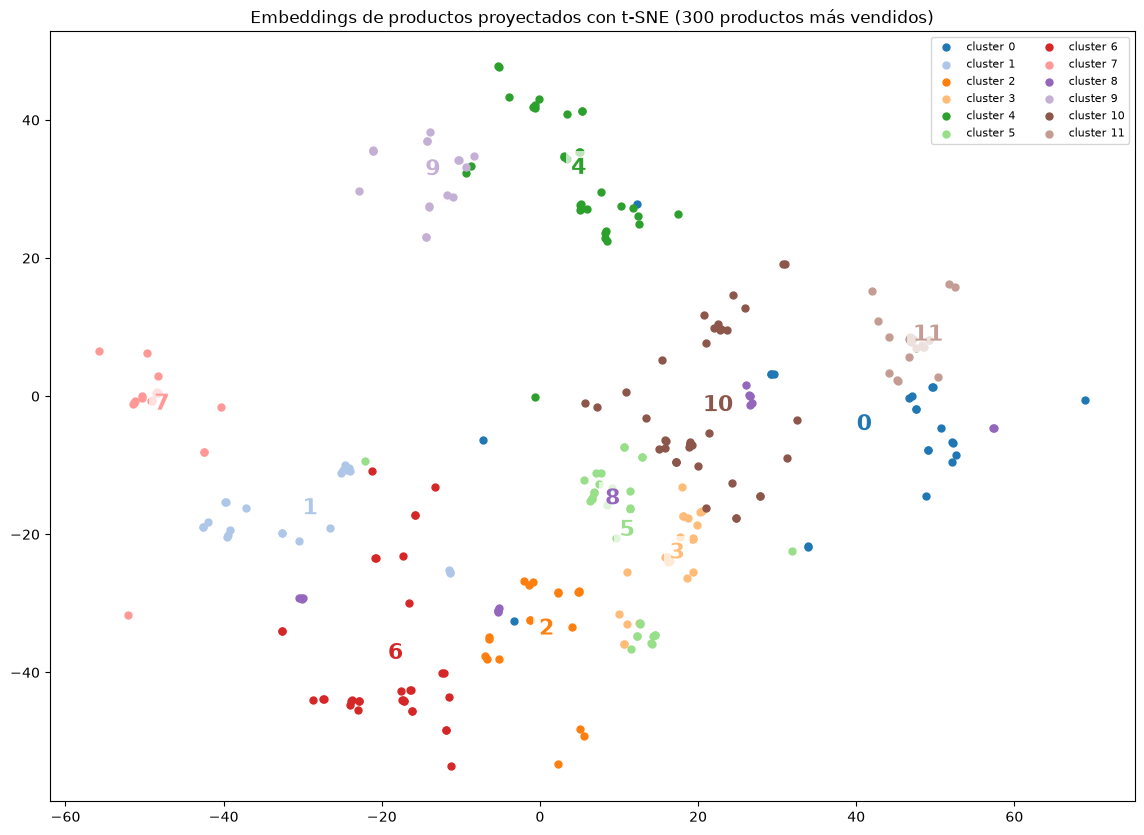

In [30]:
fig, ax = plt.subplots(figsize=(14, 10))
cmap = plt.get_cmap('tab20')
for c in range(N_CLUSTERS):
    m = clusters == c
    ax.scatter(vecs[:MAX_WORDS][m, 0], vecs[:MAX_WORDS][m, 1], s=25, color=cmap(c), label=f'cluster {c}')
    cx, cy = vecs[:MAX_WORDS][m].mean(axis=0)
    ax.text(cx, cy, str(c), fontsize=16, weight='bold', color=cmap(c),
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
ax.set_title(f'Embeddings de productos proyectados con t-SNE ({MAX_WORDS} productos más vendidos)')
ax.legend(loc='best', fontsize=8, ncol=2)
plt.show()

Interpretación: Se forman grupos bien separados. Como t-SNE y el entrenamiento no son 100% deterministas, la numeración de los clusters cambia entre ejecuciones, así que se describen por su contenido (ver el listado de productos de cada cluster de la celda anterior):
* Bolsas (*jumbo bags*, *lunch bags*, *charlotte bags*): aparecen en más de un cluster según el estampado (*retrospot*, *vintage doily*, manzanas, *paisley*). La tienda vende las bolsas en muchos diseños y los clientes compran varios juntos.
* Cocina "pantry" y té: latas para tortas y especias, recetarios, sets para hacer mermelada, tazas y tetera *Regency*, y los relojes *Bakelike*. Comparten la estética retro de cocina.
* Bolsas de agua caliente y calentadores de manos: productos de invierno, cerca de la zona navideña.
* Navidad: kits de cadenas de papel, adornos para armar, rodilleras de jardín *Keep Calm*.
* Productos infantiles: loncheras, curitas en lata, juegos tradicionales (trompos, bolos, *knitting nancy*).
* Decoración del hogar: portavelas con corazones, marcos de madera, carteles de metal con frases, banderines (*bunting*).
* Cotillón y repostería: pirotines (*cake cases*), servilletas y platos de papel *retrospot*, cortantes de galletitas.

Algunos clusters de KMeans aparecen partidos en dos zonas del t-SNE (o mezclados con otros): KMeans trabaja sobre los vectores de 100 dimensiones y t-SNE solo preserva vecindades locales, así que la distancia entre grupos lejanos en el gráfico 2D no es interpretable.

### Zoom sobre algunos grupos

En lugar de pegar capturas (que dependen de cada ejecución, porque t-SNE y el entrenamiento multi-thread no son 100% deterministas), los "zooms" se generan en código: para un producto ancla se toman sus vecinos más cercanos en el plano 2D y se grafican con su descripción. Así los grupos se reproducen siempre, aunque cambie su ubicación en el gráfico general.

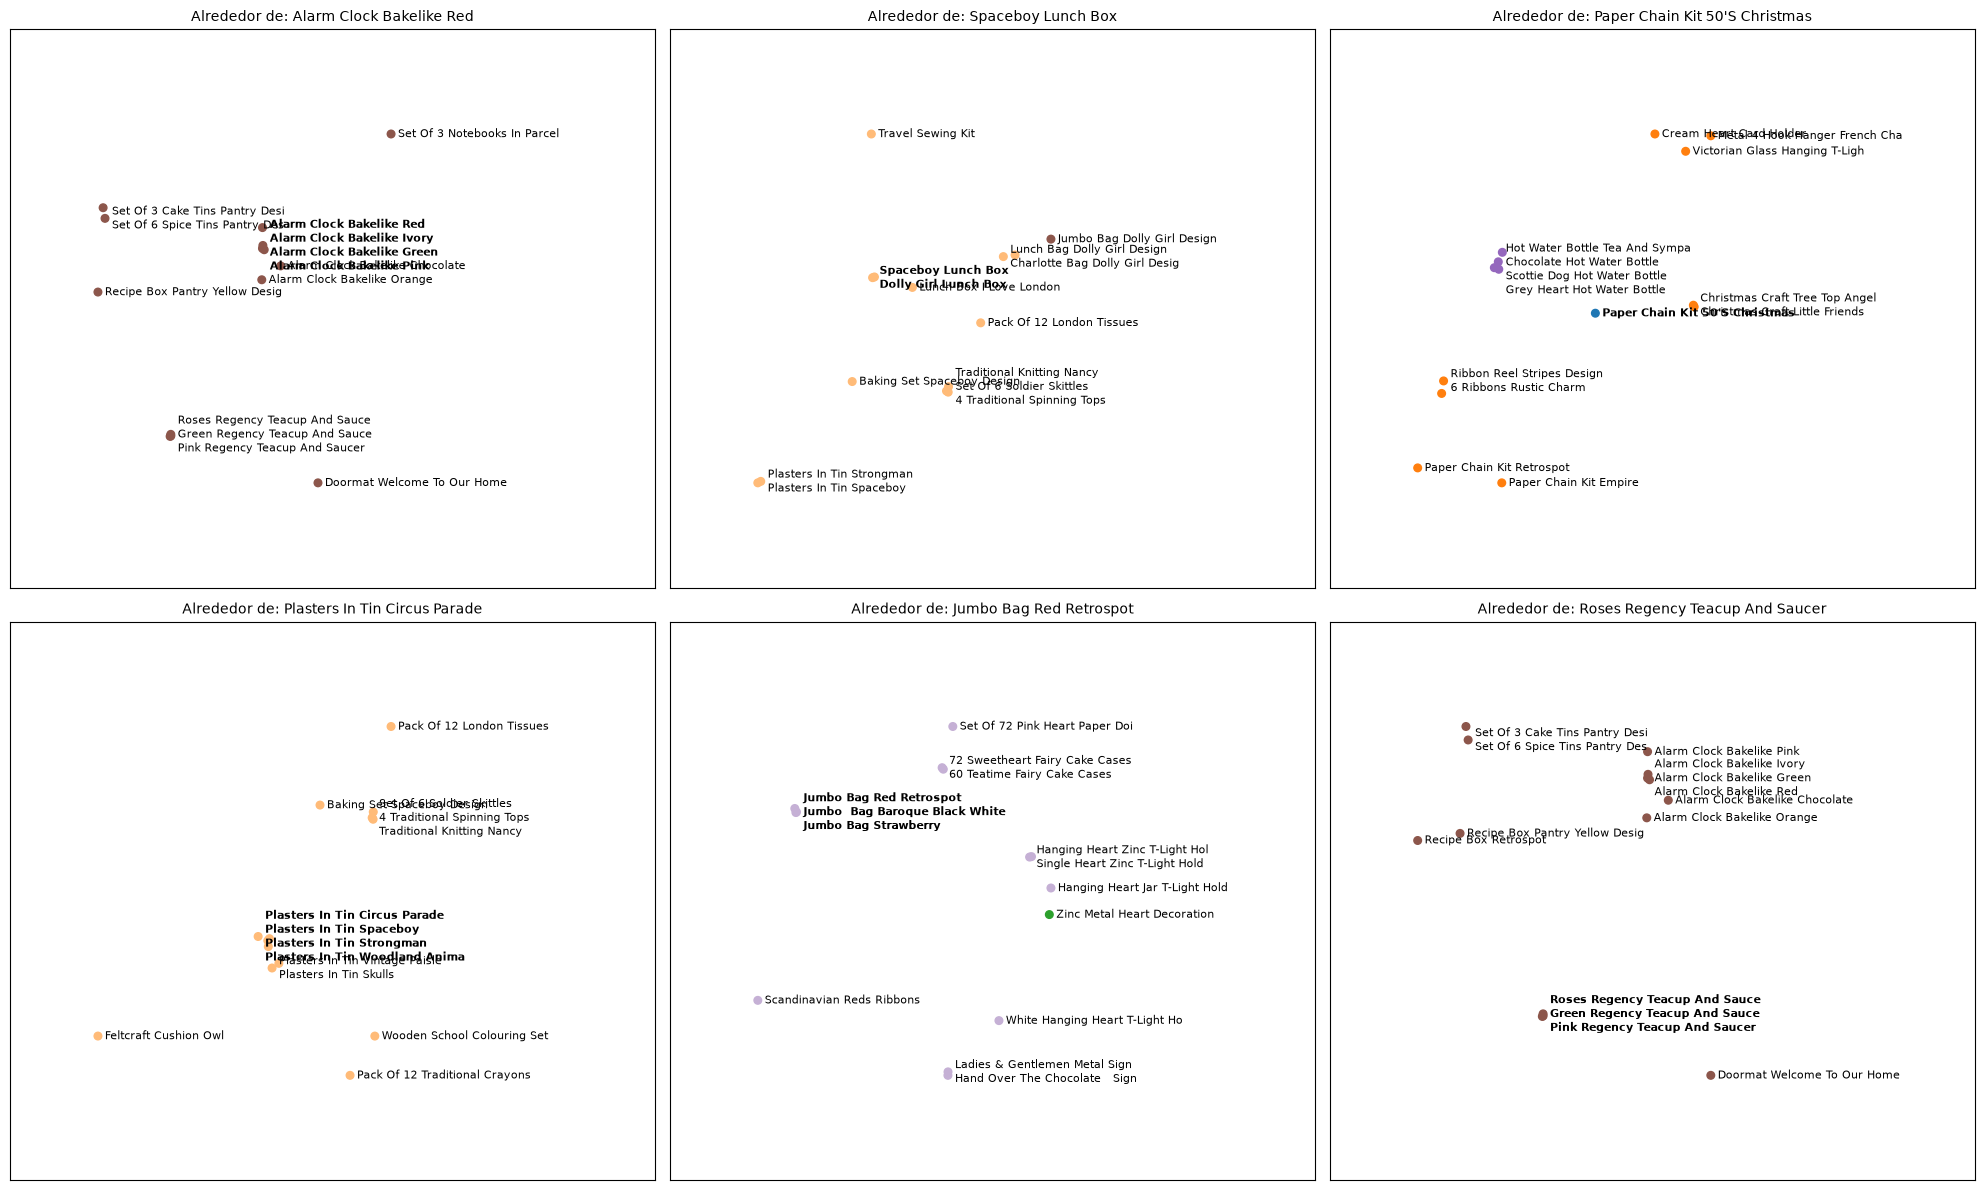

In [31]:
def zoom(ax, ancla, n=14):
    xy = vecs[:MAX_WORDS]
    i = list(labels[:MAX_WORDS]).index(ancla)
    cercanos = np.argsort(np.linalg.norm(xy - xy[i], axis=1))[:n]
    pts = xy[cercanos]
    ax.scatter(pts[:, 0], pts[:, 1], s=30, color=[cmap(c) for c in clusters[cercanos]])
    # Los puntos casi superpuestos se etiquetan juntos para que los textos no se pisen
    tol = 0.05 * np.ptp(pts, axis=0).max()
    usados = set()
    for a in range(len(cercanos)):
        if a in usados:
            continue
        grupo = [b for b in range(len(cercanos)) if b not in usados and np.linalg.norm(pts[b] - pts[a]) < tol]
        usados.update(grupo)
        texto = '\n'.join(desc[labels[cercanos[b]]][:30].title() for b in grupo)
        ax.annotate(texto, pts[a], fontsize=8, va='center', xytext=(5, 0), textcoords='offset points',
                    weight='bold' if 0 in grupo else 'normal')  # el ancla (posición 0) en negrita
    ax.set_title(f'Alrededor de: {desc[ancla].title()}', fontsize=10)
    ax.margins(0.3)
    ax.set_xlim(right=ax.get_xlim()[1] + 0.6 * np.ptp(pts[:, 0]))  # espacio para los textos
    ax.set_xticks([]); ax.set_yticks([])

# relojes, loncheras, navidad, curitas en lata, bolsas jumbo, tazas regency
anclas = ['22727', '22629', '22086', '22556', '85099B', '22699']
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for ax, ancla in zip(axes.flat, anclas):
    zoom(ax, ancla)
plt.tight_layout()
plt.show()

Interpretación:
* Relojes Bakelike: los 6 colores del reloj quedan prácticamente superpuestos, y alrededor aparece el resto de la línea de cocina retro (latas *pantry*, recetarios, tazas *Regency*). Es el grupo más compacto del gráfico.
* Loncheras: la Spaceboy y la Dolly Girl quedan superpuestas, con las *lunch/charlotte/jumbo bags* Dolly Girl al lado y, un poco más lejos, otros productos infantiles (curitas en lata, juegos tradicionales, set de repostería Spaceboy).
* Navidad: los kits de cadenas de papel y los adornos *Christmas Craft* se agrupan junto a las bolsas de agua caliente y a las cintas decorativas: un grupo estacional más que temático.
* Curitas en lata: las 6 variantes (*Circus Parade*, *Spaceboy*, *Woodland*, *Skulls*, etc.) forman un grupo compacto, rodeado de juguetes y artículos escolares tradicionales (crayones, set para colorear, trompos). Es la zona de "regalos chicos para chicos".
* Jumbo Bag Red Retrospot: las tres bolsas jumbo más vendidas quedan juntas, cerca de los best-sellers de decoración (portavelas de corazón, carteles de metal) y de los pirotines. Son productos que están en la mayoría de las facturas grandes.
* Tazas Regency: las tres tazas (rosas, verde, rosa) quedan superpuestas, cerca de los relojes y de la cocina *pantry*.

En todos los zooms se repite el mismo patrón: las variantes de un mismo producto quedan superpuestas, alrededor están los productos de la misma línea o estilo, y más lejos los de la misma ocasión de compra (temporada, público).

## Conclusiones

* Word2Vec funciona sin cambios para algo que no es texto: alcanza con definir qué es una "oración" (una factura) y qué es una "palabra" (un producto). Los embeddings capturan variantes de un mismo producto, líneas de diseño, estilos y estacionalidad sin haber visto nunca las descripciones.
* Los hiperparámetros pensados para texto no son necesariamente los mejores en recomendación. Lo más importante fue elegir skip-gram (+50% de Hit@10 sobre CBOW) y una ventana grande pero acotada (`window=20`), porque el orden dentro de la factura no importa. `ns_exponent` y `vector_size` tuvieron efectos dentro del ruido de la métrica.
* Evaluar con una métrica de recomendación (Hit@10 leave-one-out) permitió comparar configuraciones de forma objetiva. El modelo final recomienda el producto oculto entre los 10 primeros en ~24% de los casos, casi 5 veces más que recomendar lo más vendido, y elegido entre ~3400 productos.
* Los "menos similares" no tienen la interpretación de opuestos que tienen en texto: son productos de nicho que nunca se compran con el producto consultado.
* Limitaciones: el modelo no puede recomendar productos nuevos o con menos de 5 compras (*cold start*), y no usa información del cliente ni del momento de la compra. Un paso siguiente sería entrenar con las secuencias de facturas de cada cliente (para capturar recompras) o combinar los embeddings con las descripciones de los productos.